# 271. Encode and Decode Strings
**Difficulty:** 🟡 Medium (LeetCode Premium — free on neetcode.io) · **Topic:** Arrays and Hashing · **Pattern:** [String Encoding](README.md) · **LeetCode:** https://leetcode.com/problems/encode-and-decode-strings/

## 💡 Concepts

**Core concept(s):** **Length-prefix encoding** — write each string's length before it so you always know exactly how many characters to read back.

**Why it applies here:** We must pack a list of strings into one string and unpack it perfectly — even if the strings themselves contain any character (including our separators). A plain separator fails when the data contains that separator. Prefixing each piece with its length removes all ambiguity.

**Key intuition:** Say the size first, then the content: "5#hello" means "read the next 5 characters."

---

**What is length-prefix framing?**
- A *frame* is one chunk of data plus the information needed to find where it ends.
- Length-prefix framing puts the chunk's size in front: `"4#lint"` = length `4`, a `#` marker, then 4 characters of content.
- The reader never searches the content for an end marker; it reads the number and jumps exactly that far.
- Cost: encode and decode each touch every character once, **O(total length)**; the header adds only `digits + 1` characters per string.
- In Python: `str(len(w)) + "#" + w` to write a frame; `int(s[i:j])` and the slice `s[start:start + length]` to read one back.

**What is a delimiter (separator)?**
- A delimiter is a character placed *between* items to mark where one ends, like `,` in CSV.
- It only works if the delimiter never appears *inside* an item. Here strings may contain **any** character, so no choice of delimiter is safe on its own.
- In Python: `"#".join(items)` and `s.split("#")`, both **O(total length)**.

**What are string slicing and joining?**
- `s[a:b]` copies the characters from index `a` up to (not including) `b`: **O(b − a)**.
- `"".join(parts)` glues a list of strings together in one pass: **O(total length)**. Repeated `+=` in a loop can re-copy the growing string, so building a list and joining once is the safe habit.

---

**Prerequisite knowledge:**
- Basic string building and slicing.
- Why a delimiter alone is unsafe (the data might contain it).

## 📝 Problem

Design `encode(list_of_strings) -> string` and `decode(string) -> list_of_strings` so decoding restores the original list exactly. Strings may contain **any** characters.

**Example**
```
["lint","code"] -> encode -> "4#lint4#code" -> decode -> ["lint","code"]
```

**More examples**
```
["a#b", "3#weird"] -> "3#a#b7#3#weird" -> ["a#b", "3#weird"]   # '#' inside the data is fine
[""]               -> "0#"             -> [""]                 # one empty string
[]                 -> ""               -> []                   # no strings at all
```

**Constraints (LeetCode 271)**
- `1 <= strs.length <= 200` (the notebook also tests the empty list)
- `0 <= strs[i].length <= 200`
- `strs[i]` may contain any of the 256 valid ASCII characters
- `encode` must be stateless: `decode` gets only the encoded string, no extra memory shared between them.

> Two approaches: a naive delimiter (shown to fail) and the correct length-prefix scheme.

### Approach 1 — Join with a Separator (naive — it breaks)

**Idea:** Glue strings with a special character like `#`. Fails whenever a string *contains* `#`, because decode can't tell data from separator.

**Time complexity:** `O(total length)`.

**Space complexity:** `O(total length)`.

In [1]:
from typing import List

def encode_naive(strs: List[str]) -> str:
    # Join with a '#'. UNSAFE: breaks if any string itself contains '#'.
    return "#".join(strs)

def decode_naive(s: str) -> List[str]:
    # Splitting on '#' can't tell a real '#' apart from a separator.
    return s.split("#") if s != "" else []

### Approach 2 — Length Prefix (correct)

**Idea:** For each string write `len(str) + "#" + str`. To decode, read digits up to `#` to get the length, then read exactly that many characters — so the content can safely contain anything.

**Time complexity:** `O(total length)`.

**Space complexity:** `O(total length)`.

In [2]:
from typing import List

def encode(strs: List[str]) -> str:
    parts = []
    for w in strs:
        # Write "<length>#<content>" so the reader knows exactly how far to read.
        parts.append(str(len(w)) + "#" + w)
    return "".join(parts)                  # concatenate all the framed chunks

def decode(s: str) -> List[str]:
    res = []
    i = 0
    while i < len(s):                      # keep reading chunks until the string ends
        j = i
        while s[j] != "#":                 # read digits up to the '#' marker
            j += 1
        length = int(s[i:j])               # those digits are the content length
        start = j + 1                      # content begins right after the '#'
        res.append(s[start:start + length])# take exactly `length` characters (any char is safe)
        i = start + length                 # jump to the start of the next chunk
    return res

In [3]:
# Correctness check — round-trip must return the original, even with tricky characters
tests = [
    ["lint","code"],
    ["", "", ""],
    ["a#b", "3#weird", "we#ird"],            # contains the separator!
    [],
]
for strs in tests:
    round_correct = decode(encode(strs))
    print(f"{strs} -> {round_correct}")
    assert round_correct == strs, "length-prefix round-trip failed!"

# show the naive version breaking on separators-in-data
broken = decode_naive(encode_naive(["a#b"]))
print("\nnaive on ['a#b'] ->", broken, "(wrong — split on the # inside the data)")
assert broken != ["a#b"], "expected the naive approach to fail here"
print("\nAll tests passed")

['lint', 'code'] -> ['lint', 'code']
['', '', ''] -> ['', '', '']
['a#b', '3#weird', 'we#ird'] -> ['a#b', '3#weird', 'we#ird']
[] -> []

naive on ['a#b'] -> ['a', 'b'] (wrong — split on the # inside the data)

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on inputs of growing `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(n)`        | ≈ **2×** |
| `O(n log n)`  | ≈ **2×** (slightly more) |
| `O(n²)`       | ≈ **4×** |
| `O(n³)`       | ≈ **8×** |

Inputs are built to force the **worst case** (no early exit). Sub-millisecond rows are noisy — look at the trend.


naive   O(total)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     4000 |       0.20 |           n/a
     8000 |       0.17 |         0.84x
    16000 |       0.43 |         2.53x
    32000 |       0.74 |         1.72x

correct O(total)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
     4000 |       0.92 |           n/a
     8000 |       1.83 |         1.99x
    16000 |       3.64 |         1.98x
    32000 |       7.22 |         1.99x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


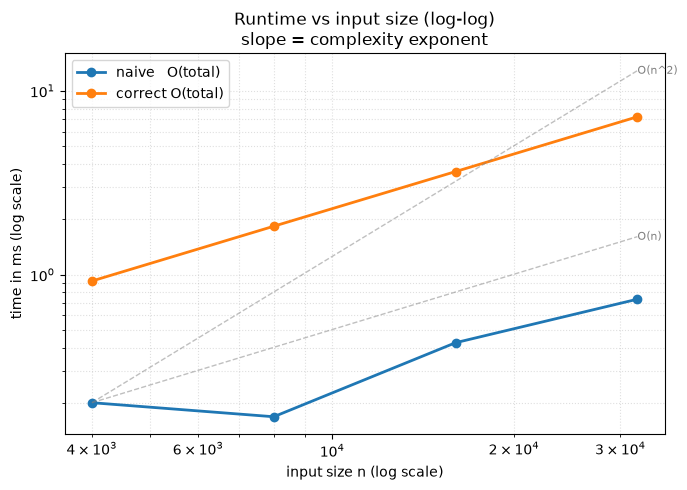

{'naive   O(total)': [0.20108302123844624,
  0.1686250325292349,
  0.42620894964784384,
  0.7350420346483588],
 'correct O(total)': [0.9229580173268914,
  1.8330840393900871,
  3.6352500319480896,
  7.220958010293543]}

In [4]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark   # shared: prints ratio table + optional log-log plot

def rt_naive(strs):   return decode_naive(encode_naive(strs))
def rt_correct(strs): return decode(encode(strs))

def make_worst_case(n):
    strs = ["hello"] * n                     # no separators, so both round-trip cleanly
    return (strs,)

solutions = {
    "naive   O(total)": rt_naive,
    "correct O(total)": rt_correct,
}
sizes = [4000, 8000, 16000, 32000]

benchmark(solutions, make_worst_case, sizes, plot=True)


## 🧩 Patterns Learned

- **Pattern:** [String Encoding](README.md) — each string is framed as `len + "#" + content`, so decode reads the length first and then slices exactly that many characters, whatever they are.
- **Length-prefix framing:** state a chunk's size before its content so you can read it back with zero ambiguity — the same idea used in real network protocols.
- **Separators are unsafe alone:** any in-band marker can appear in the data; a length tells you exactly how far to read.
- **Signal:** "serialize / deserialize", "pack a list into one string", "encode with arbitrary characters".
- **Related problems:** Serialize and Deserialize Binary Tree, string tokenizers, protocol design.
- **Common pitfalls:** (1) using a delimiter the data may contain; (2) off-by-one when slicing after the `#`.